# renders.py

*Generated from `renders.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
renders.py -- ray-traced renders of the lattices and cells used in the simulations.

    VK_ICD_FILENAMES=/usr/share/vulkan/icd.d/lvp_icd.json python3 renders.py
    (needs pip install ovito and a Vulkan driver, e.g. apt install mesa-vulkan-drivers)

Writes ../renders/:
  R1_wc_supercell.png      the 8x5x8 WC cell (1280 atoms): 3D, down c, down a
  R2_v3_clusters.png       the eight v3 vacancy clusters with 4 He, as placed by
                           make_v3.py (needs ../../he_be_v3)
  R3_reference_phases.png  the six reference crystals of in.phases at their relaxed
                           lattice constants (needs ../../wc_ef)
  R4_point_defects.png     the formation-energy defect cells from make_ef.py

Colours: W gray, C blue, He yellow, vacancy red, added atom green.  Close-ups
show host atoms within 7 A of the defect, semi-transparent.
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'renders.py'
NB_RENDERS = os.path.join("..", "renders")   # where renders.py writes
ARGS = []              # needs OVITO, and ../../he_be_v3, ../../wc_ef for R2-R4
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

The cells below are the script.  They need the run's dumps (and OVITO where it is imported), so they were not run when this notebook was built; the outputs further down come from a cluster run.

In [ ]:
import glob
import os
import re

import numpy as np
from PIL import Image, ImageDraw, ImageFont

from ovito.data import DataCollection, ParticleType
from ovito.pipeline import Pipeline, StaticSource
from ovito.vis import Viewport, TachyonRenderer

In [ ]:
HERE = os.path.dirname(os.path.abspath(__file__))
ROOT = os.path.join(HERE, "..")
OUT = os.path.join(ROOT, "renders")
os.makedirs(OUT, exist_ok=True)
V3 = os.path.join(ROOT, "..", "he_be_v3")
EF = os.path.join(ROOT, "..", "wc_ef")

A, C = 2.91861599, 2.81497613            # relaxed 0 K lattice (res_bulk.dat)
B = np.sqrt(3.0) * A
NX, NY, NZ = 8, 5, 8
TYPES = {1: ("W", (0.55, 0.55, 0.55), 0.95), 2: ("C", (0.16, 0.47, 0.84), 0.55),
         3: ("He", (0.95, 0.76, 0.18), 0.6), 4: ("vacancy", (0.84, 0.18, 0.18), 0.75),
         5: ("added", (0.11, 0.69, 0.48), 0.6)}
SIZE = (560, 460)
FONT = "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
if not os.path.exists(FONT):
    FONT = None


def font(sz, bold=False):
    f = FONT.replace("DejaVuSans.ttf", "DejaVuSans-Bold.ttf") if bold and FONT else FONT
    return ImageFont.truetype(f, sz) if f else ImageFont.load_default()

In [ ]:
# ---------------------------------------------------------------- structures
def wc_cell(nx=NX, ny=NY, nz=NZ):
    basis = [(0, 0, 0, 1), (0.5, 0.5, 0, 1), (0, 2 / 3, 0.5, 2), (0.5, 1 / 6, 0.5, 2)]
    P, T = [], []
    for i in range(nx):
        for j in range(ny):
            for k in range(nz):
                for (u, v, w, t) in basis:
                    P.append(((i + u) * A, (j + v) * B, (k + w) * C))
                    T.append(t)
    return np.array(P), np.array(T), np.array([nx * A, ny * B, nz * C])


def frac_to_xyz(f):
    return np.array([f[0] * A, f[1] * B, f[2] * C])


def read_data(fn):
    L, P, T, on = [], [], [], False
    for line in open(fn):
        if "xlo xhi" in line or "ylo yhi" in line or "zlo zhi" in line:
            a, b = map(float, line.split()[:2])
            L.append(b - a)
        if line.startswith("Atoms"):
            on = True
            continue
        if on and line.strip():
            v = line.split()
            T.append(int(v[1]))
            P.append(tuple(map(float, v[2:5])))
    return np.array(P), np.array(T), np.array(L)


def parse_cfg(fn):
    """vacated sites and He positions (fractions of the cell grid) from a make_v3/make_ef cfg"""
    vac, add = [], []
    pat = r"\$\(xlo\+([\d.]+)\*lx/(\d+)\) \$\(ylo\+([\d.]+)\*ly/(\d+)\) \$\(zlo\+([\d.]+)\*lz/(\d+)\)"
    for line in open(fn):
        m = re.search(pat, line)
        if not m:
            continue
        f = (float(m.group(1)), float(m.group(3)), float(m.group(5)))
        if line.startswith("region") and "core" not in line:
            vac.append((f, "C" if "# C" in line else "W"))
        elif line.startswith("create_atoms"):
            add.append((f, int(line.split()[1])))
    return vac, add

In [ ]:
# ---------------------------------------------------------------- rendering
def render(P, T, L, fn, cam=(-1, -1.5, -0.9), ortho=True, show_cell=True, transp=None,
           fov=None, size=SIZE, cell_line=0.12, zoom=1.0, radius=None):
    data = DataCollection()
    m = np.zeros((3, 4))
    m[0, 0], m[1, 1], m[2, 2] = L
    cell = data.create_cell(m, pbc=(True, True, True))
    cell.vis.enabled = show_cell
    cell.vis.line_width = cell_line
    cell.vis.rendering_color = (0.35, 0.35, 0.35)
    parts = data.create_particles(count=len(P))
    parts.create_property("Position", data=P)
    tp = parts.create_property("Particle Type", data=T)
    for t, (name, col, r) in TYPES.items():
        tp.types.append(ParticleType(id=t, name=name, color=col, radius=r))
    if transp is not None:
        parts.create_property("Transparency", data=transp)
    if radius is not None:
        parts.create_property("Radius", data=radius)
    pipe = Pipeline(source=StaticSource(data=data))
    pipe.add_to_scene()
    vp = Viewport(type=Viewport.Type.Ortho if ortho else Viewport.Type.Perspective, camera_dir=cam)
    vp.zoom_all()
    if zoom != 1.0:
        vp.fov = vp.fov / zoom
    if fov:
        vp.fov = fov
    vp.render_image(size=size, filename=fn, background=(1, 1, 1),
                    renderer=TachyonRenderer(ambient_occlusion=True, antialiasing_samples=12,
                                             shadows=False))
    pipe.remove_from_scene()


def closeup(P, T, L, center, extra_P, extra_T, fn, R=5.2, cam=(-0.55, -1.0, -0.45), host_alpha=0.78):
    """host atoms within R of center (minimum image, re-centred), semi-transparent"""
    d = P - center
    d -= L * np.round(d / L)
    keep = np.linalg.norm(d, axis=1) < R
    hp = d[keep] + R + 1
    ht = T[keep]
    ep = np.array(extra_P).reshape(-1, 3)
    if len(ep):
        e = ep - center
        e -= L * np.round(e / L)
        ep = e + R + 1
    allP = np.vstack([hp, ep]) if len(ep) else hp
    allT = np.concatenate([ht, np.array(extra_T, int)]) if len(ep) else ht
    tr = np.concatenate([np.full(len(hp), host_alpha),
                         np.array([0.5 if t == 4 else 0.0 for t in extra_T])]) if len(ep) else np.full(len(hp), host_alpha)
    box = np.full(3, 2 * R + 2)
    rad = np.array([{1: 0.55, 2: 0.32, 3: 0.62, 4: 0.7, 5: 0.6}[t] for t in allT])
    rad[:len(hp)] = np.array([{1: 0.55, 2: 0.32}[t] for t in ht])
    render(allP, allT, box, fn, cam=cam, show_cell=False, transp=tr, radius=rad, zoom=1.15)


def montage(files, labels, out, ncol, title=None, sub=None, legend=True):
    ims = [Image.open(f).convert("RGB") for f in files]
    w, h = ims[0].size
    lab_h, top = 46, (64 if title else 8) + (24 if sub else 0)
    leg_h = 46 if legend else 0
    nrow = (len(ims) + ncol - 1) // ncol
    M = Image.new("RGB", (w * ncol, top + nrow * (h + lab_h) + leg_h), "white")
    d = ImageDraw.Draw(M)
    if title:
        d.text((16, 14), title, fill=(11, 11, 11), font=font(26, True))
    if sub:
        d.text((16, 52), sub, fill=(82, 81, 78), font=font(17))
    for i, (im, lab) in enumerate(zip(ims, labels)):
        x, y = (i % ncol) * w, top + (i // ncol) * (h + lab_h)
        M.paste(im, (x, y + lab_h))
        lines = lab.split("\n")
        d.text((x + 14, y + 4), lines[0], fill=(11, 11, 11), font=font(19, True))
        if len(lines) > 1:
            d.text((x + 14, y + 26), lines[1], fill=(82, 81, 78), font=font(15))
    if legend:
        y = M.size[1] - leg_h + 12
        x = 18
        for t in (1, 2, 3, 4, 5):
            name, col, r = TYPES[t]
            c = tuple(int(255 * v) for v in col)
            d.ellipse((x, y, x + 20, y + 20), fill=c, outline=(60, 60, 60))
            d.text((x + 28, y), {"added": "added atom (interstitial / antisite)"}.get(name, name),
                   fill=(11, 11, 11), font=font(16))
            x += 60 + 9 * len(name) + (230 if name == "added" else 40)
    M.save(out)
    print("wrote", out)


TMP = os.path.join(OUT, "_tiles")
os.makedirs(TMP, exist_ok=True)

In [ ]:
# ---------------------------------------------------------------- R1
def r1():
    P, T, L = wc_cell()
    f = []
    render(P, T, L, os.path.join(TMP, "r1a.png"), cam=(-1, -1.5, -0.9), ortho=False, size=(700, 560))
    render(P, T, L, os.path.join(TMP, "r1b.png"), cam=(0, 0, -1), size=(700, 560))
    render(P, T, L, os.path.join(TMP, "r1c.png"), cam=(0, 1, 0), size=(700, 560))
    montage([os.path.join(TMP, x) for x in ("r1a.png", "r1b.png", "r1c.png")],
            ["3D view\n8 x 5 x 8 orthogonal cells, 1280 atoms (640 W + 640 C)",
             "view down c [0001]\n%.2f x %.2f A; W-W in-plane a = %.4f A" % (L[0], L[1], A),
             "view down y\nW layers (z = 0) and C layers (z = c/2), c = %.4f A" % C],
            os.path.join(OUT, "R1_wc_supercell.png"), 3,
            title="WC simulation cell (all v3 and formation-energy runs)",
            sub="hexagonal WC in an orthogonal a x sqrt(3)a x c cell; periodic in x, y, z; "
                "%.2f x %.2f x %.2f A at the 0 K lattice" % tuple(L), legend=False)

In [ ]:
# ---------------------------------------------------------------- R2
SER = [("vw1", "V_W"), ("vw2", "(V_W)2, c-axis"), ("vw2a", "(V_W)2, in-plane"), ("vw3", "(V_W)3"),
       ("vc1", "V_C"), ("vwc", "V_W V_C"), ("vwc2", "V_W (V_C)2"), ("vw2c2", "(V_W)2 (V_C)2")]


def r2():
    P, T, L = wc_cell()
    files, labels = [], []
    for s, lab in SER:
        fn = os.path.join(V3, "cfg", "%s_14.lmp" % s)
        vac, he = parse_cfg(fn)
        vxyz = np.array([frac_to_xyz(f) for f, _ in vac])
        keep = np.ones(len(P), bool)
        for v in vxyz:
            keep &= np.linalg.norm(P - v, axis=1) > 0.3
        cen = vxyz.mean(axis=0)
        extra = [frac_to_xyz(f) for f, _ in he] + list(vxyz)
        et = [3] * len(he) + [4] * len(vxyz)
        out = os.path.join(TMP, "r2_%s.png" % s)
        closeup(P[keep], T[keep], L, cen, extra, et, out)
        files.append(out)
        labels.append("%s + 4 He\n%s, trial 1, as placed (before CG)" % (lab, s))
    montage(files, labels, os.path.join(OUT, "R2_v3_clusters.png"), 4,
            title="v3 vacancy clusters, as placed by make_v3.py",
            sub="host atoms within 5.2 A of the cluster centre, small and translucent; red = vacated site, "
                "yellow = He (4 He, trial 1 of 4)")

In [ ]:
# ---------------------------------------------------------------- R3
RELAXED = {  # lx ly lz from your res_phases.dat
    "bccW": (12.659854, 12.659854, 12.659854), "graphite": (10.064740, 13.074481, 13.400000),
    "diamond": (10.680344, 10.680344, 10.680344), "W2C": (11.941339, 15.512254, 20.162599),
    "hexWC": (11.674464, 15.165574, 11.259905), "rsWC": (13.149497, 13.149497, 13.149497)}
PH = [("bccW", "bcc W", "a = 3.1650 A; eps_W = -8.8901 eV/atom; W-rich limit"),
      ("graphite", "graphite (= graphene here)", "a = 2.516 A; eps_C = -7.3612 eV/atom; C-rich limit"),
      ("diamond", "diamond", "a = 3.5601 A; 45 meV/atom above graphite"),
      ("W2C", "W2C (CdI2 type)", "a = 2.985, c = 5.041 A; +1.59 eV/f.u. above WC + W"),
      ("hexWC", "hexagonal WC", "a = 2.9186, c = 2.8150 A; dH_f = -0.409 eV/f.u."),
      ("rsWC", "rocksalt WC", "a = 4.383 A; +0.98 eV/f.u. above hexagonal")]


def r3():
    files, labels = [], []
    for name, lab, sub in PH:
        P, T, L = read_data(os.path.join(EF, "phases", name + ".data"))
        s = np.array(RELAXED[name]) / L
        out = os.path.join(TMP, "r3_%s.png" % name)
        cam = {"graphite": (-0.35, -1.0, -0.12), "W2C": (-0.6, -1.0, -0.25)}.get(name, (-1, -1.6, -0.8))
        render(P * s, T, L * s, out, cam=cam)
        files.append(out)
        labels.append(lab + "\n" + sub)
    montage(files, labels, os.path.join(OUT, "R3_reference_phases.png"), 3,
            title="Reference crystals of in.phases (same potential as WC)",
            sub="drawn at the box your run relaxed to; they fix the chemical-potential window "
                "for the formation energies", legend=False)

In [ ]:
# ---------------------------------------------------------------- R4
DEF = [("01", "V_W", "E_f 3.67 (W-rich) / 3.26 (C-rich)"), ("02", "V_C", "E_f 0.52 / 0.93"),
       ("03", "V_C pair, c-axis", "binding -0.46 eV (repel)"), ("04", "V_C pair, in-plane", "binding -0.25 eV (repel)"),
       ("05", "V_W + V_C", "E_f 3.81 (any mu); binding +0.38"),
       ("06", "C_i, channel site (lowest)", "E_f 3.22 / 2.81; same site as He"),
       ("11", "C_i, C-C dumbbell along a", "0.79 eV above the channel site"),
       ("16", "W_i, W-W dumbbell along a", "E_f 12.34 / 12.74 (relaxes off-site)"),
       ("18", "W on a C site", "E_f 9.22 / 10.03"), ("19", "C on a W site", "relaxes toward the channel; 6.75 / 5.93")]


def r4():
    P, T, L = wc_cell()
    files, labels = [], []
    for k, lab, sub in DEF:
        vac, add = parse_cfg(os.path.join(EF, "cfg", "def_%s.lmp" % k))
        vxyz = np.array([frac_to_xyz(f) for f, _ in vac]).reshape(-1, 3)
        axyz = np.array([frac_to_xyz(f) for f, _ in add]).reshape(-1, 3)
        keep = np.ones(len(P), bool)
        for v in vxyz:
            keep &= np.linalg.norm(P - v, axis=1) > 0.3
        cen = np.vstack([vxyz, axyz]).mean(axis=0)
        # mark vacated sites only where nothing was put back
        vmark = [v for v in vxyz if not len(axyz) or np.min(np.linalg.norm(axyz - v, axis=1)) > 0.3
                 and not (len(axyz) == 2 and np.linalg.norm(axyz.mean(axis=0) - v) < 0.3)]
        extra = list(axyz) + vmark
        et = [5] * len(axyz) + [4] * len(vmark)
        out = os.path.join(TMP, "r4_%s.png" % k)
        closeup(P[keep], T[keep], L, cen, extra, et, out, R=5.0)
        files.append(out)
        labels.append(lab + "\n" + sub)
    montage(files, labels, os.path.join(OUT, "R4_point_defects.png"), 5,
            title="Formation-energy defect cells, as built by make_ef.py",
            sub="host within 5 A, small and translucent; formation energies from your run "
                "(W-rich / C-rich, eV)")

In [ ]:
if __name__ == "__main__":
    r1(); r2(); r3(); r4()

## Outputs

Renders from the binding-energy runs (made with OVITO's Tachyon renderer).

In [2]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


R1_wc_supercell.png


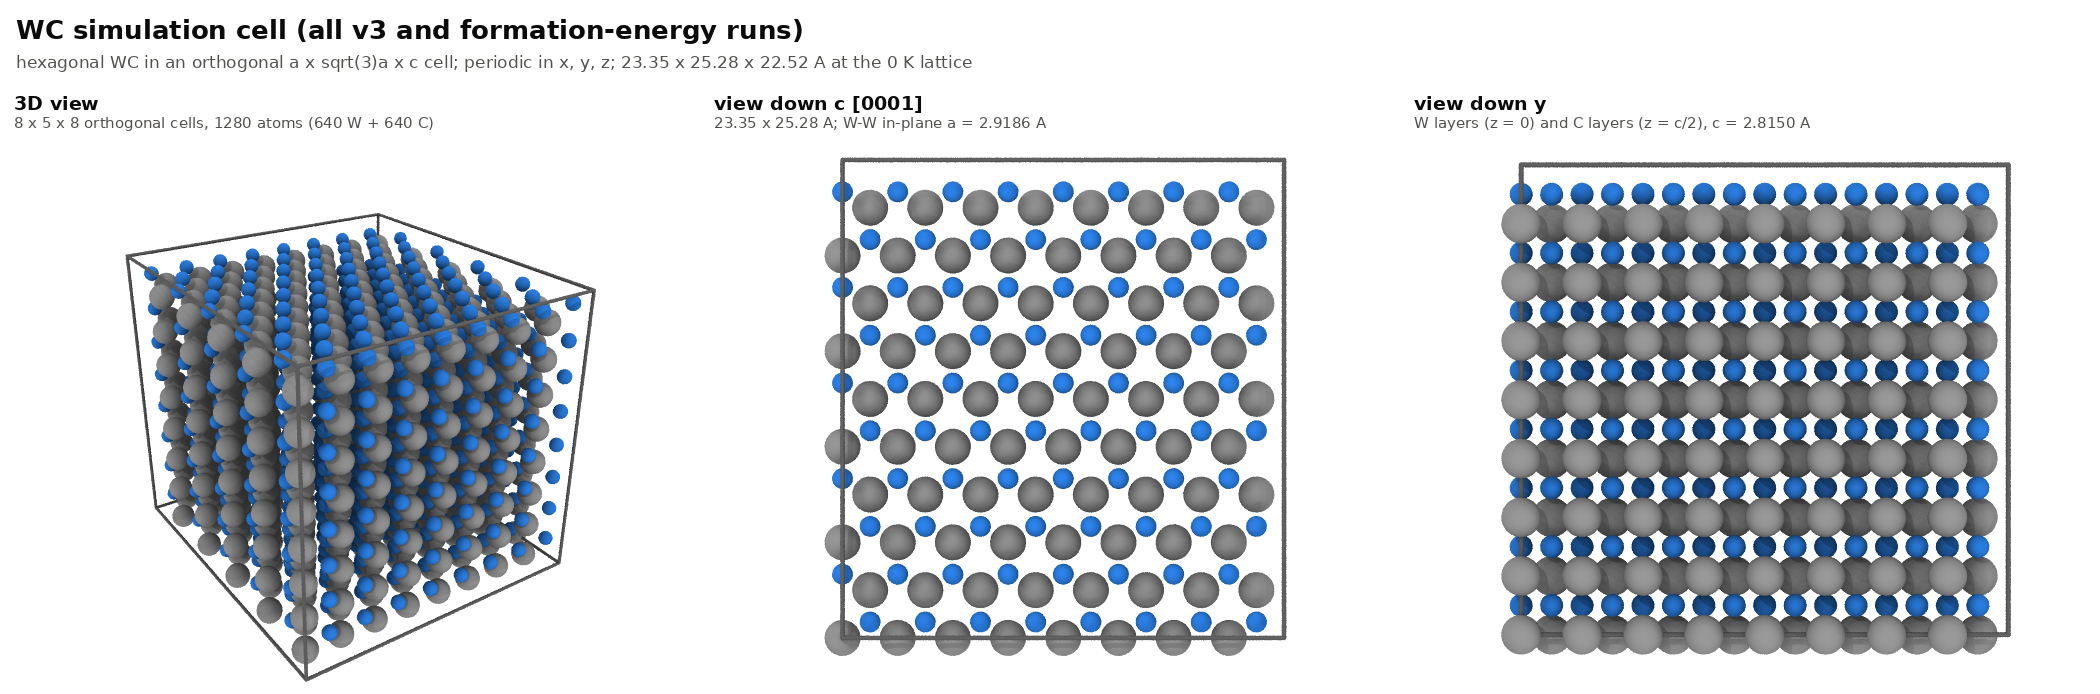

R2_v3_clusters.png


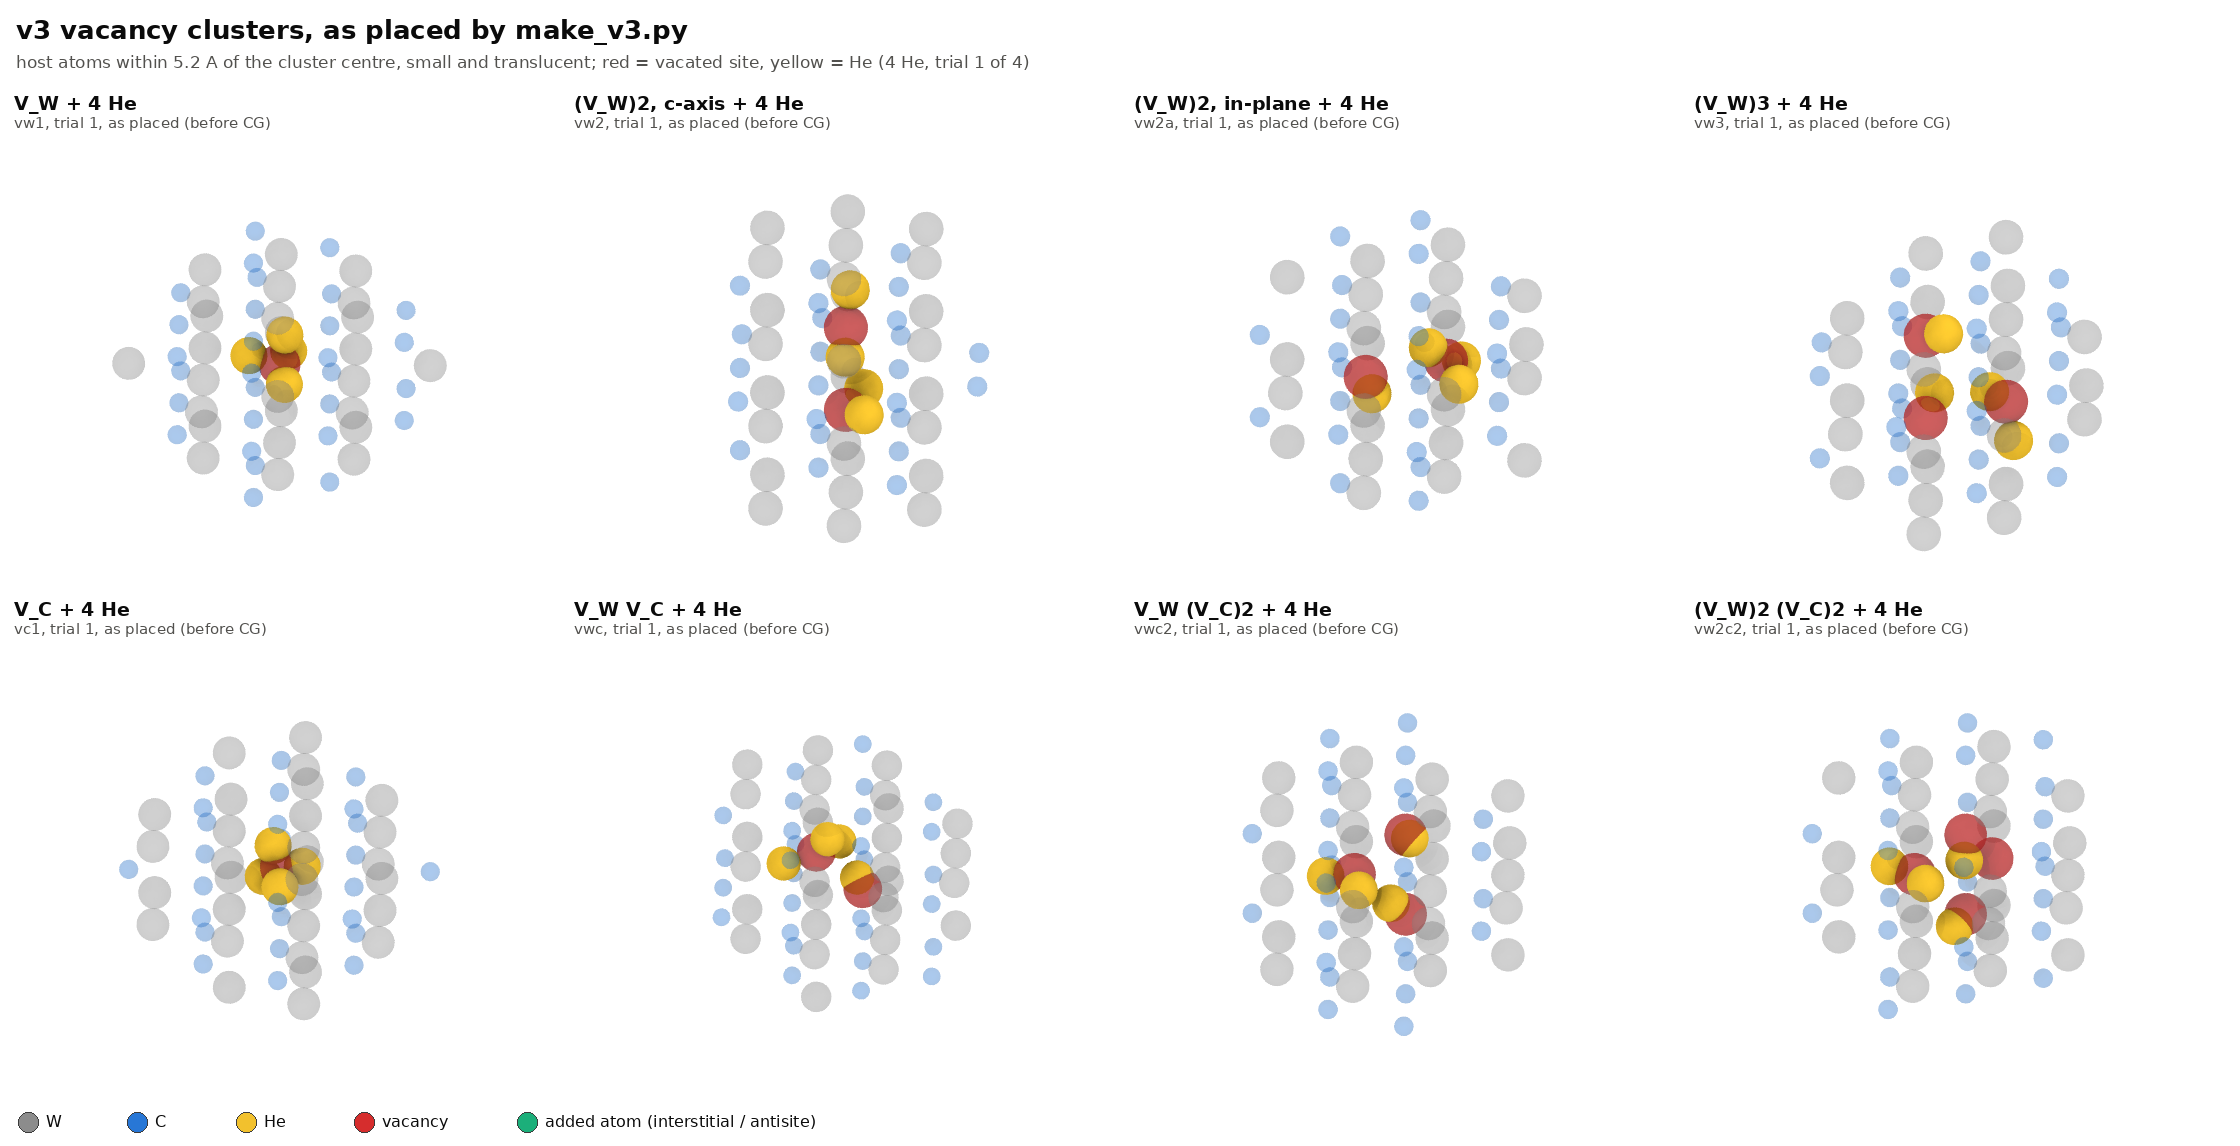

R3_reference_phases.png


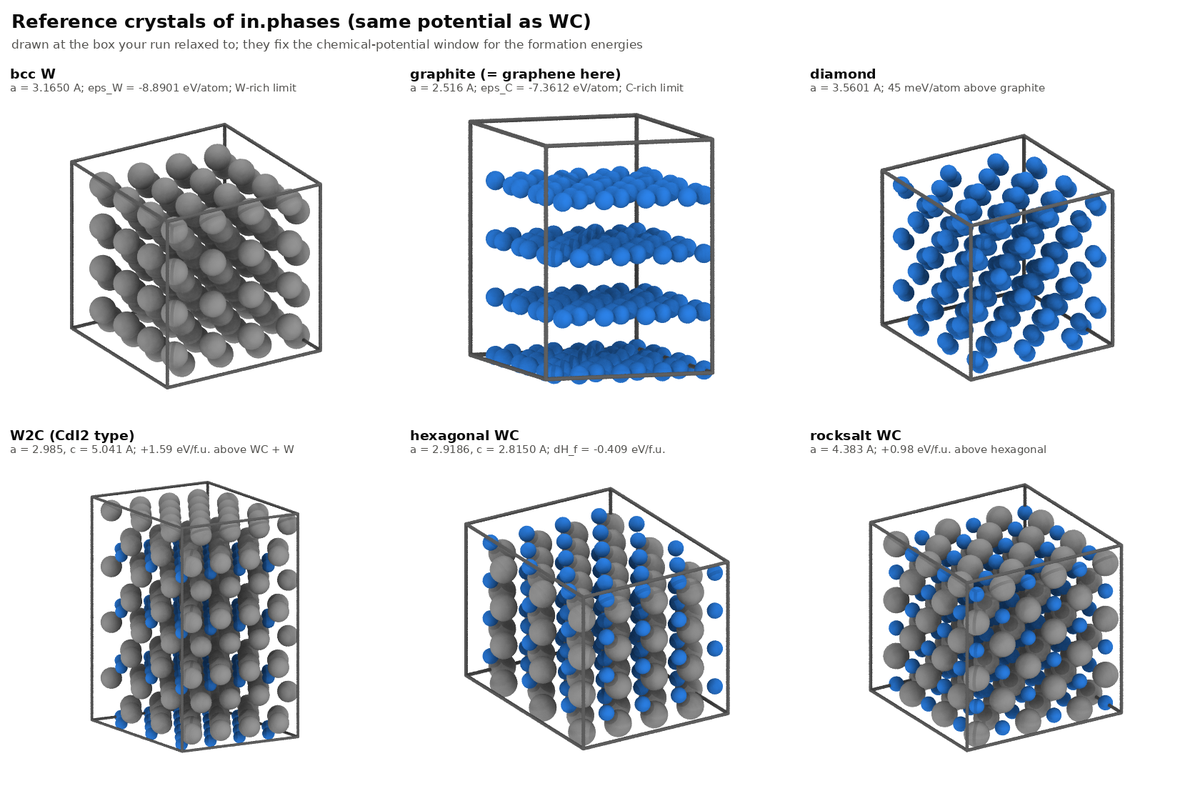

R4_point_defects.png


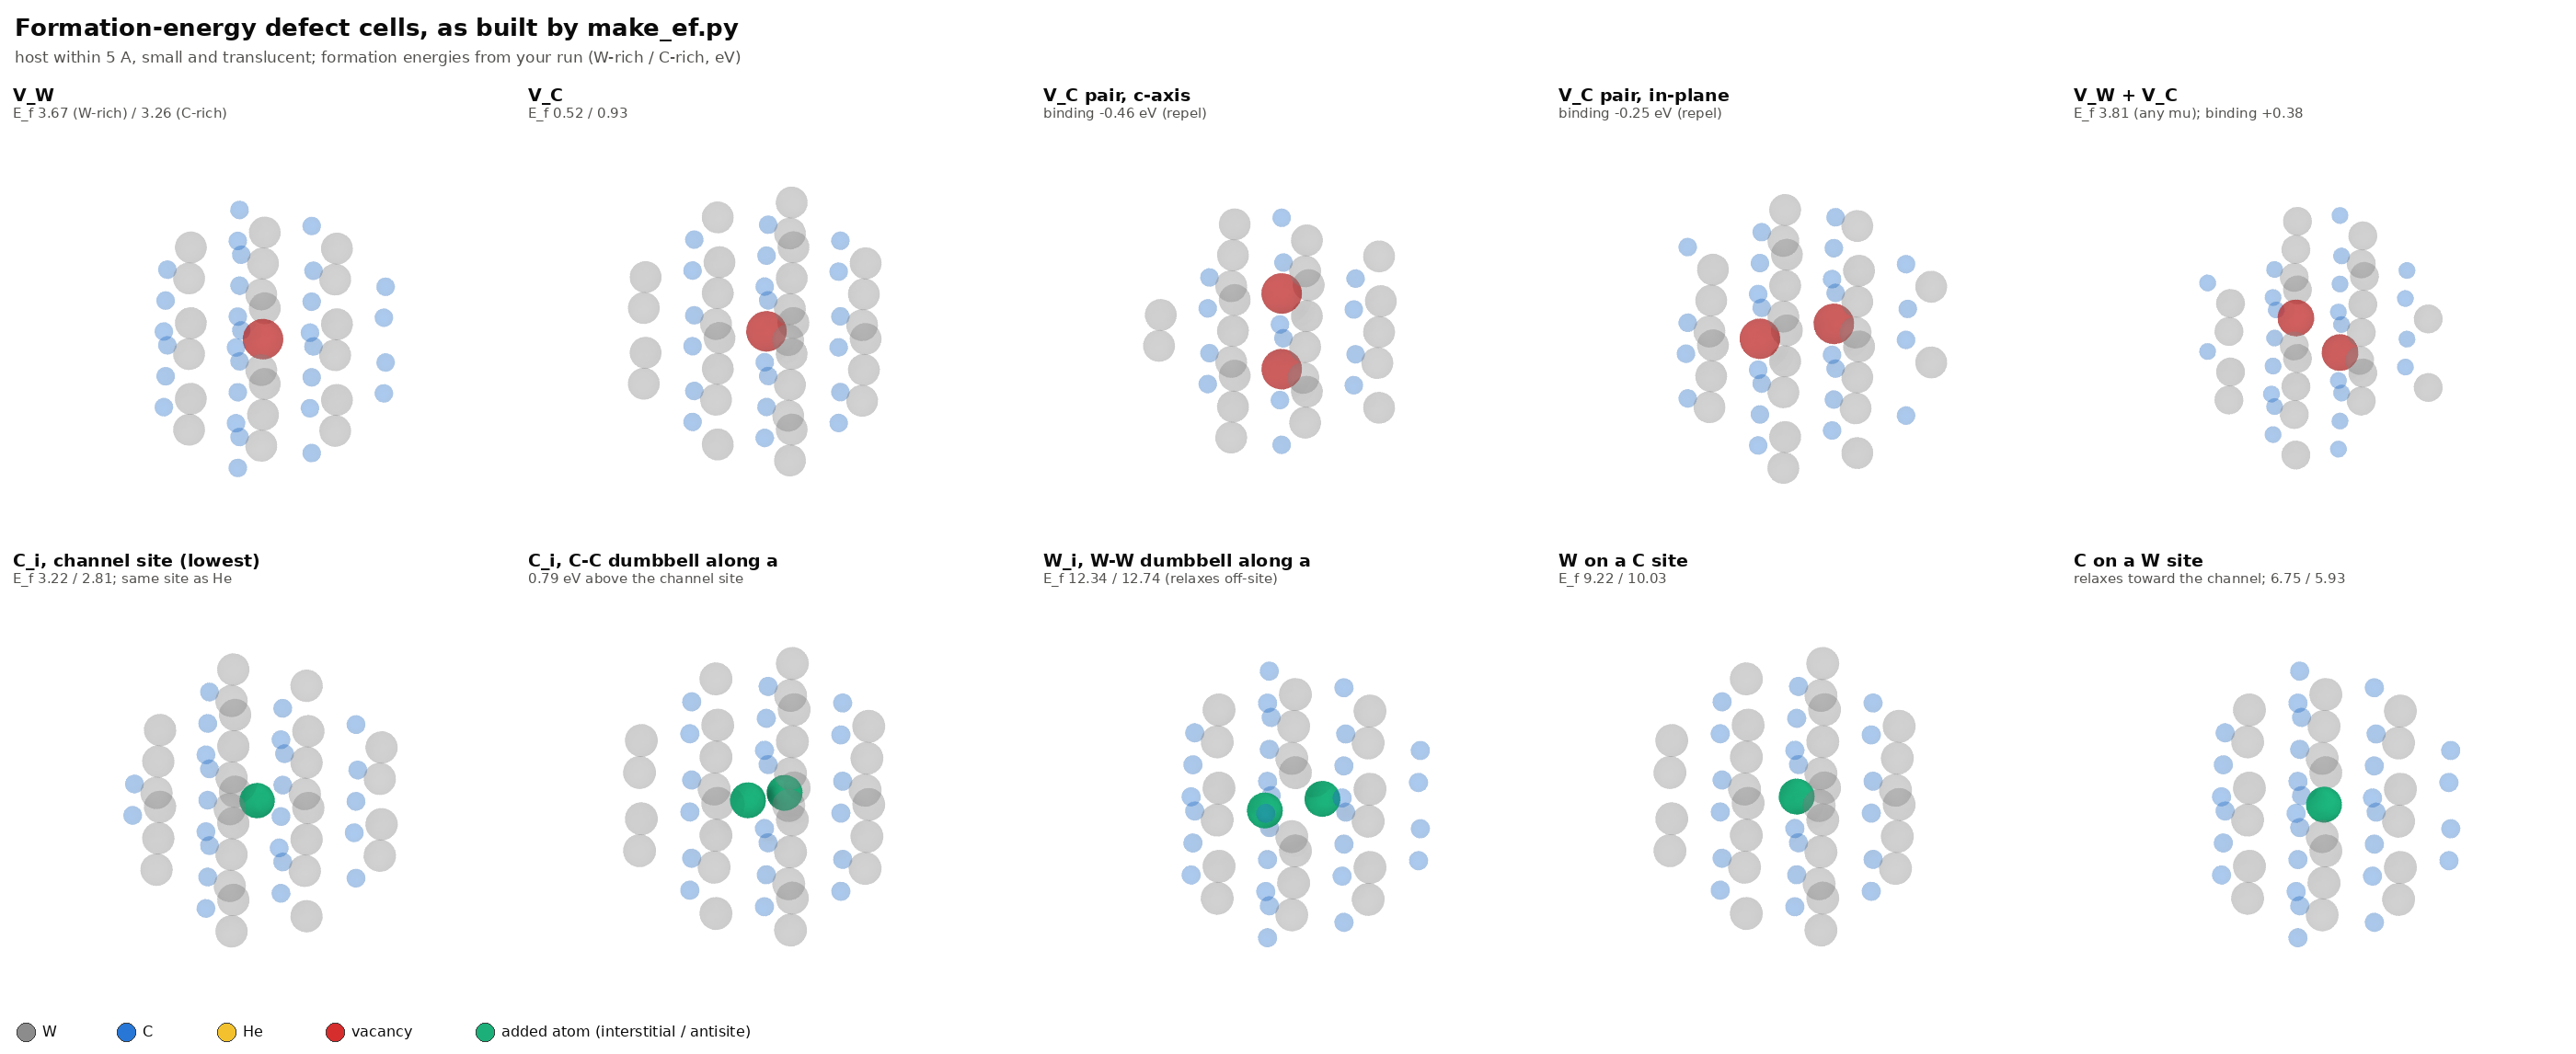

In [3]:
show(NB_RENDERS, ['R1_wc_supercell.png', 'R2_v3_clusters.png', 'R3_reference_phases.png', 'R4_point_defects.png'])